In [1]:
from typing import List,TypedDict,Literal
from pydantic import BaseModel

import re

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS

from langchain_text_splitters import RecursiveCharacterTextSplitter

from langchain_ollama import ChatOllama,OllamaEmbeddings

from langchain_core.prompts import ChatPromptTemplate
from langchain_core.documents import Document


from langgraph.graph import StateGraph,START,END


/var/folders/zd/wq0h2pzd4ks66gj19y5_p7br0000gn/T/ipykernel_79771/2249936087.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
/Users/ryankhurana/Desktop/CRAG-Corrective-RAG-/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.
/Users/ryankhurana/Desktop/CRAG-Corrective-RAG-/venv/lib/python3.13/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a

In [2]:
docs=(PyPDFLoader("./documents/book1.pdf").load()+
      PyPDFLoader("./documents/book2.pdf").load()+
      PyPDFLoader("./documents/book3.pdf").load())

In [3]:
len(docs)

2123

In [4]:
chunks=RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)

In [5]:
embedding=OllamaEmbeddings(model="nomic-embed-text")

In [6]:
#cleaning the chunks(removing broken or invalid characters from each text chunk)
for d in chunks:
    d.page_content=d.page_content.encode("utf-8","ignore").decode("utf-8","ignore")

In [7]:
vector_store=FAISS.from_documents(chunks,embedding)
retriever=vector_store.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [8]:
llm=ChatOllama(model="llama3.1:8b")

In [9]:
UPPER_TH=0.7
LOWER_TH=0.3

In [10]:
class State(TypedDict):
    question:str
    docs:List[str]

    good_docs:List[Document]#List of those documents that have got threshold more than the upper threshold
    verdict:str#[3 options correct ,incorrect and ambiguous]
    reason:str# contains the reason for the verdict

    strips:List[str]
    kept_strings:List[str]
    refined_context:str

    ans:str

In [11]:
def retrieve(state:State)->State:
    retrieved_docs=retriever.invoke(state['question'])
    return {"docs":retrieved_docs}

In [12]:
#Evaluator
class Doc_String_evaluator(BaseModel):
    score:float
    reason:str
doc_evaluator_prompt=ChatPromptTemplate.from_messages([
   ( "system",
    "You are a strict retrieval evaluator for RAG.\n"
            "You will be given ONE retrieved chunk and a question.\n"
            "Return a relevance score in [0.0, 1.0].\n"
            "- 1.0: chunk alone is sufficient to answer fully/mostly\n"
            "- 0.0: chunk is irrelevant\n"
            "Be conservative with high scores.\n"
            "Also return a short reason.\n"
            "Output JSON only."),
            (
                ("human","Question: {question}\n\nChunk: {chunk}")#here chunk is referring to the docs not the sentences(as we want our llm to rate our docs and then decide which docs are worthy and which are not)
            )
    
])
llm_with_structured_output=llm.with_structured_output(Doc_String_evaluator)
doc_eval_chain=doc_evaluator_prompt|llm_with_structured_output



def eval_each_doc(state:State)->State:
    #extract the question
    q=state['question']

    scores:List[float]=[]
    reason:List[str]=[]
    good:List[Document]=[]
    
    for d in state['docs']:
        out=doc_eval_chain.invoke({"question":q,"chunk":d.page_content})
        scores.append(out.score)
        reason.append(out.reason)
        if out.score>LOWER_TH:
            good.append(d)
        #CORRECT IF at least one doc >UPPER_TH
    if any(s>UPPER_TH for s in scores):
        return{
            "good_docs": good,
            "verdict": "CORRECT",
            "reason": f"At least one retrieved chunk scored > {UPPER_TH}.",
        }
    #all([])=>True edge case (so check length)
    if len(scores)>0 and all(s<LOWER_TH for s in scores):
        #only those will be rejected where all the docs score below the lower bound if anything is above lowerbound then it will come under ambiguous
        why = "No chunk was sufficient."
        return {
            "good_docs": [],
            "verdict": "INCORRECT",
            "reason": f"All retrieved chunks scored < {LOWER_TH}. {why}",
        }
    
    # 4) Anything in between => AMBIGUOUS
    why = "Mixed relevance signals."
    return {
        "good_docs": good,
        "verdict": "AMBIGUOUS",
        "reason": f"No chunk scored > {UPPER_TH}, but not all were < {LOWER_TH}. {why}",
    }

In [13]:
def decompose_to_sentences(text: str) -> List[str]:
    text = re.sub(r"\s+", " ", text).strip()
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 20]

In [14]:
class KeepORDrop(BaseModel):
    keep:bool

filter_prompt=ChatPromptTemplate.from_messages(
    [
        ("system","You are a strict relevance filter.\n"
            "Return keep=true only if the sentence directly helps answer the question.\n"
            "Use ONLY the sentence. Output JSON only."),
        ("human","Question:{question}\n\nSentences\n{Sentences}")
         
    ]
)
llm_with_keep_drop=llm.with_structured_output(KeepORDrop)
filter_chain=filter_prompt|llm_with_keep_drop

def refine(state:State)->State:
    q=state['question']
    context="\n\n".join( d.page_content for d in state['good_docs'])
    strips=decompose_to_sentences(context)
    #now we have broken down the strips then we have to filter on the basis of how relevant are these to the question
    kept:List[str]=[]
    for s in strips:
        if filter_chain.invoke({"question":q,"Sentences":s}).keep:
            kept.append(s)
    refined_context="\n".join(s for s in kept).strip()


    return {
            "strips": strips,
            "kept_strips": kept,
            "refined_context": refined_context,
        }

In [15]:
answer_prompt=ChatPromptTemplate.from_messages([
   ("system",
    "You are a helpful ML tutor. Answer ONLY using the provided context.\n"
            "If the context is empty or insufficient, say: 'I don't know.'",) ,
    ("human","Question{question}\n\nRefined context{refined_context}")
])
def generate_answer(state:State)->State:
    out_chain=answer_prompt|llm
    output= out_chain.invoke({"question":state['question'],"refined_context":state['refined_context']})
    return {"answer":output.content}



In [16]:
def fail_node(state:State)->State:
    return {"answer": f"FAIL: {state['reason']}"}
def ambigous_node(state:State)->State:
    return {"answer":f"Fail:{state['reason']}"}
def route_after_eval(state:State)->str:
    if state['verdict']=="CORRECT":
        return 'refine'
    elif state['verdict']=="INCORRECT":
        return "web_search"
    else:
        return "ambiguous"
    



In [17]:
g=StateGraph(State)
g.add_node("retrieve",retrieve)
g.add_node("eval_each_doc",eval_each_doc)
g.add_node("refine",refine)
g.add_node("generate",generate_answer)
g.add_node("fail", fail_node)
g.add_node("ambiguous",ambigous_node)

In [18]:
#creating edges btw the nodes
g.add_edge(START,"retrieve")
g.add_edge("retrieve","eval_each_doc")
g.add_conditional_edges(
    "eval_each_doc",
    route_after_eval,                 #fail=failnode
    {"refine": "refine", "web_search": "fail", "ambiguous": "ambiguous"}   
)
g.add_edge("refine", "generate")
g.add_edge("generate", END)
g.add_edge("ambiguous",END)
g.add_edge("fail", END)


In [19]:
app=g.compile()


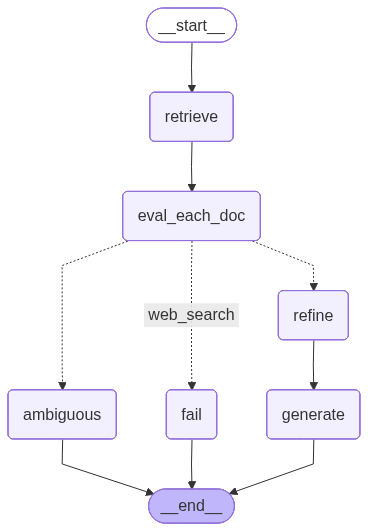

In [20]:
app

In [24]:
res = app.invoke(
    {
        "question": "explain KNN?",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "answer": "",
    }
)


In [30]:
res = app.invoke(
    {
        "question": "what is KNN?",
        "docs": [],
        "good_docs": [],
        "verdict": "",
        "reason": "",
        "strips": [],
        "kept_strips": [],
        "refined_context": "",
        "answer": "",
    }
)

print("VERDICT:", res["verdict"])
print("REASON:", res["reason"])
print("\nOUTPUT:\n", res.get("answer", "No answer in state"))

VERDICT: INCORRECT
REASON: All retrieved chunks scored < 0.3. No chunk was sufficient.

OUTPUT:
 No answer in state
